# Torrent vs Regular Download Hypothesis Test
Use this notebook to inspect data and prepare values for SocSciStatistics t-test.

In [1]:
# ── 0. Install / Import Libraries ─────────────────────────────────────────────
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)   # reproducibility
print('Libraries loaded ✓')

Libraries loaded ✓


In [2]:
# ── 1. Generate Full Dataset ───────────────────────────────────────────────────
POPULATION_MEAN_H0 = 45          # claimed / null mean (regular download speed MB/s)
TRUE_MEAN          = 52          # actual torrent download speed mean
SIGMA              = 6           # known population std dev
N_FULL             = 200         # total dataset size

# Simulated torrent download speeds
speeds = np.random.normal(loc=TRUE_MEAN, scale=SIGMA, size=N_FULL)
speeds = np.clip(speeds, 10, 100)   # realistic range

df_full = pd.DataFrame({
    'download_id': np.arange(1, N_FULL + 1),
    'speed_mbps':  np.round(speeds, 2)
})

print(f'Dataset shape : {df_full.shape}')
print(f'Sample mean   : {df_full.speed_mbps.mean():.4f}')
print(f'Sample std    : {df_full.speed_mbps.std():.4f}')
df_full.head(10)

Dataset shape : (200, 2)
Sample mean   : 51.7553
Sample std    : 5.5860


,download_id,speed_mbps
0,1,54.98
1,2,51.17
2,3,55.89
3,4,61.14
4,5,50.60
5,6,50.60
6,7,61.48
7,8,56.60
8,9,49.18
9,10,55.26


## Hypotheses
- H0: Torrent downloads are not faster than regular downloads.
- H1: Torrent downloads are faster than regular downloads.

count    200.000000
mean      51.755350
std        5.585973
min       36.280000
25%       47.770000
50%       51.975000
75%       55.005000
max       68.320000


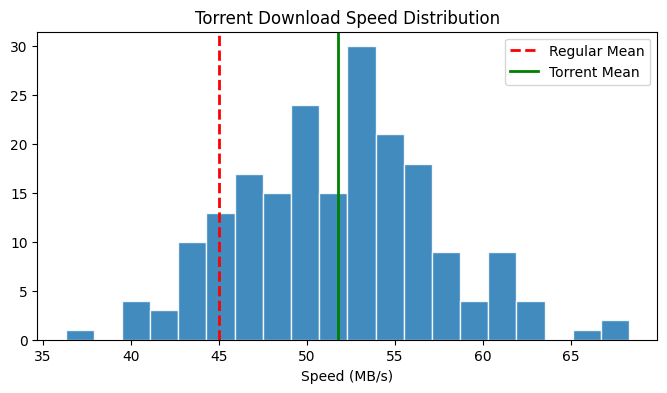

In [3]:
# ── 1b. Descriptive Statistics ─────────────────────────────────────────────────
desc = df_full['speed_mbps'].describe().rename('Speed Statistics')
print(desc.to_string())

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(df_full['speed_mbps'], bins=20, alpha=0.85, edgecolor='white')
ax.axvline(POPULATION_MEAN_H0, color='red', lw=2, ls='--', label='Regular Mean')
ax.axvline(df_full.speed_mbps.mean(), color='green', lw=2, label='Torrent Mean')
ax.set_title('Torrent Download Speed Distribution')
ax.set_xlabel('Speed (MB/s)')
ax.legend()
plt.show()

In [4]:
# ── 2. Z-Test Loop ─────────────────────────────────────────────────────────────
sample_sizes = [4, 9, 16, 25, 36, 49, 64, 100]
ALPHA = 0.05

rows = []

for n in sample_sizes:
    sample = df_full['speed_mbps'].iloc[:n].values
    x_bar  = sample.mean()
    se     = SIGMA / np.sqrt(n)
    z_stat = (x_bar - POPULATION_MEAN_H0) / se
    p_val  = 2 * (1 - stats.norm.cdf(abs(z_stat)))

    decision = 'Reject H₀' if p_val < ALPHA else 'Do not reject H₀'

    rows.append({
        'n': n,
        'Sample Mean': round(x_bar,2),
        'SE': round(se,3),
        'Z Statistic': round(z_stat,3),
        'p-value': round(p_val,5),
        'Decision': decision
    })

df_z = pd.DataFrame(rows)
df_z

,n,Sample Mean,SE,Z Statistic,p-value,Decision
0,4,55.80,3.000,3.598,0.00032,Reject H₀
1,9,54.63,2.000,4.813,0.00000,Reject H₀
2,16,51.85,1.500,4.566,0.00000,Reject H₀
3,25,51.02,1.200,5.017,0.00000,Reject H₀
4,36,51.02,1.000,6.023,0.00000,Reject H₀
5,49,50.84,0.857,6.808,0.00000,Reject H₀
6,64,50.85,0.750,7.802,0.00000,Reject H₀
7,100,51.38,0.600,10.628,0.00000,Reject H₀


In [5]:
# ── 3. One-Sample T-Test ───────────────────────────────────────────────────────
print('='*60)
print('ONE SAMPLE T-TEST')
print('='*60)

t_rows = []

for n in sample_sizes:
    sample = df_full['speed_mbps'].iloc[:n].values
    t_stat, p_val = stats.ttest_1samp(sample, popmean=POPULATION_MEAN_H0)

    t_rows.append({
        'n': n,
        'Sample Mean': round(sample.mean(),2),
        't Statistic': round(t_stat,3),
        'p-value': round(p_val,5)
    })

df_t = pd.DataFrame(t_rows)
df_t

ONE SAMPLE T-TEST


,n,Sample Mean,t Statistic,p-value
0,4,55.80,5.255,0.01342
1,9,54.63,6.283,0.00024
2,16,51.85,4.701,0.00028
3,25,51.02,5.244,0.00002
4,36,51.02,6.433,0.00000
5,49,50.84,7.430,0.00000
6,64,50.85,8.696,0.00000
7,100,51.38,11.702,0.00000


In [6]:
# ── 4. Independent Two-Sample T-Test ──────────────────────────────────────────
# Control = Regular Download
# Treatment = Torrent Download

control   = np.random.normal(loc=45, scale=6, size=50)
treatment = df_full['speed_mbps'].iloc[:50].values

t_stat_2, p_val_2 = stats.ttest_ind(treatment, control, equal_var=False)

print('='*60)
print('INDEPENDENT TWO SAMPLE T-TEST')
print('='*60)
print('Torrent Mean :', round(treatment.mean(),2))
print('Regular Mean :', round(control.mean(),2))
print('t-statistic  :', round(t_stat_2,3))
print('p-value      :', round(p_val_2,5))

if p_val_2 < 0.05:
    print('Conclusion   : Torrent is significantly faster.')
else:
    print('Conclusion   : No significant difference.')

INDEPENDENT TWO SAMPLE T-TEST
Torrent Mean : 50.65
Regular Mean : 45.91
t-statistic  : 3.889
p-value      : 0.00019
Conclusion   : Torrent is significantly faster.


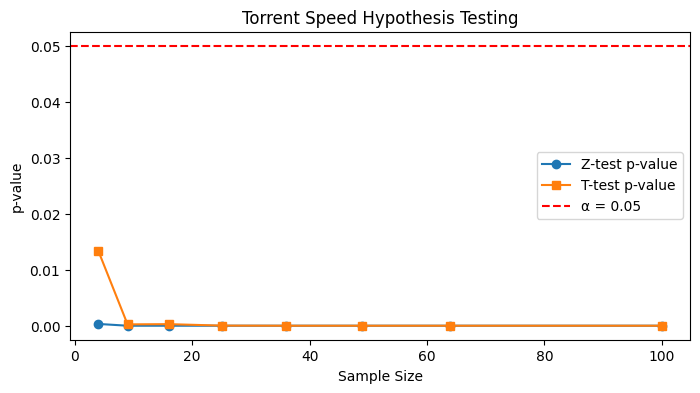

In [7]:
# ── 5. Visual Comparison ───────────────────────────────────────────────────────
plt.figure(figsize=(8,4))
plt.plot(df_z['n'], df_z['p-value'], marker='o', label='Z-test p-value')
plt.plot(df_t['n'], df_t['p-value'], marker='s', label='T-test p-value')
plt.axhline(0.05, color='red', linestyle='--', label='α = 0.05')
plt.xlabel('Sample Size')
plt.ylabel('p-value')
plt.title('Torrent Speed Hypothesis Testing')
plt.legend()
plt.show()

In [8]:
# ── 6. Export Files ────────────────────────────────────────────────────────────
df_full.to_csv('torrent_dataset.csv', index=False)
df_z.to_csv('torrent_z_test_results.csv', index=False)
df_t.to_csv('torrent_t_test_results.csv', index=False)

print('Files saved ✓')

Files saved ✓
